In [5]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv(r'C:\Users\World\Downloads\Compressed/ecommerce_dataset_updated.csv')
df

,User_ID,Product_ID,Category,Price (Rs.),Discount (%),Final_Price(Rs.),Payment_Method,Purchase_Date
0,337c166f,f414122f-e,Sports,36.53,15,31.05,Net Banking,12-11-2024
1,d38a19bf,fde50f9c-5,Clothing,232.79,20,186.23,Net Banking,09-02-2024
2,d7f5f0b0,0d96fc90-3,Sports,317.02,25,237.76,Credit Card,01-09-2024
3,395d4994,964fc44b-d,Toys,173.19,25,129.89,UPI,01-04-2024
4,a83c145c,d70e2fc6-e,Beauty,244.80,20,195.84,Net Banking,27-09-2024
...,...,...,...,...,...,...,...,...
3655,67abda0a,28714133-6,Beauty,486.79,0,486.79,UPI,14-05-2024
3656,34ebc1a0,08838c2c-9,Toys,212.87,15,180.94,Cash on Delivery,19-11-2024
3657,1defd3b1,c39a4f16-6,Home & Kitchen,389.76,0,389.76,Net Banking,07-08-2024
3658,0611293d,b4f67f96-9,Electronics,447.66,30,313.36,UPI,21-05-2024


In [4]:
df.isna().sum()

User_ID             0
Product_ID          0
Category            0
Price (Rs.)         0
Discount (%)        0
Final_Price(Rs.)    0
Payment_Method      0
Purchase_Date       0
dtype: int64

<Axes: xlabel='Discount (%)'>

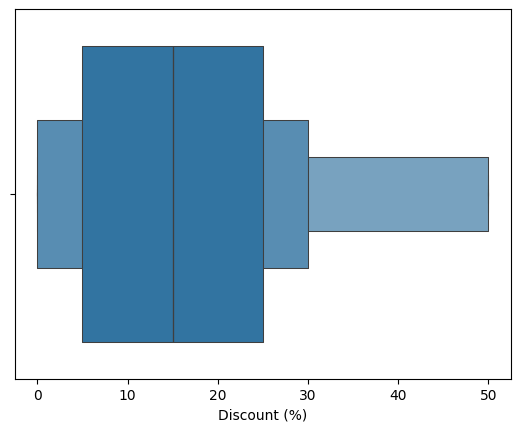

In [14]:
sns.boxenplot(x=df['Price (Rs.)'],data=df)

In [ ]:
pd.pivot_table(df,values=['Price (Rs.)',])

In [26]:
df.agg({'Price (Rs.)': 'mean'})

Price (Rs.)    254.800675
dtype: float64

In [29]:
df.groupby('Category').agg(
    avg_price=('Price (Rs.)', 'mean'),
    max_price=('Price (Rs.)', 'max')
)

,avg_price,max_price
Category,,
Beauty,252.738693,499.65
Books,259.123052,499.36
Clothing,263.115913,499.91
Electronics,251.646867,496.76
Home & Kitchen,249.255938,499.03
Sports,258.619212,499.96
Toys,248.962772,499.00


AttributeError: 'DataFrame' object has no attribute 'na'

np.float64(0.0)

In [33]:
df.shape

(3660, 8)

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# Create a realistic dataset with common data issues
n_samples = 500

data = {
    'age': np.random.normal(35, 12, n_samples),  # Normal distribution around age 35
    'salary': np.random.lognormal(10.2, 0.6, n_samples),  # Log-normal (realistic for salaries)
    'education_years': np.random.randint(8, 22, n_samples),  # Years of education
    'work_experience': np.random.exponential(7, n_samples),  # Exponential distribution
    'credit_score': np.random.normal(650, 120, n_samples),  # Credit scores
    'city': np.random.choice(['New York', 'Los Angeles', 'Chicago', 'Houston', 'Miami'], n_samples),
    'job_type': np.random.choice(['Full-Time', 'Part-Time', 'Contract', 'Unemployed'], n_samples),
    'house_price': None  # We'll create this as our target variable
}

df = pd.DataFrame(data)

# Create target variable (house price) based on other features
df['house_price'] = (
    df['salary'] * 2.5 + 
    df['age'] * 1000 + 
    df['education_years'] * 5000 + 
    df['credit_score'] * 50 +
    np.random.normal(0, 15000, n_samples)  # Add some randomness
)

# 🔍 INTRODUCE REAL-WORLD DATA ISSUES:

# 1. Missing Values (5-10% missing in some columns)
for col in ['salary', 'credit_score', 'education_years']:
    mask = np.random.random(n_samples) < 0.08  # 8% missing
    df.loc[mask, col] = np.nan

# 2. Outliers (extreme values that don't make sense)
df.loc[20:25, 'salary'] *= 5    # Extremely high salaries
df.loc[30:35, 'age'] = 150      # Impossible ages
df.loc[40:45, 'credit_score'] = 300  # Extremely low credit scores

# 3. Invalid values
df.loc[50:55, 'education_years'] = -5  # Negative education years
df.loc[60:65, 'work_experience'] = 100 # Unrealistic work experience

# 4. Duplicate rows (5% duplicates)
duplicate_indices = np.random.choice(df.index, size=25, replace=False)
df = pd.concat([df, df.loc[duplicate_indices]], ignore_index=True)

# 5. Inconsistent text data
df.loc[70:75, 'city'] = 'NY'  # Inconsistent city naming
df.loc[80:85, 'job_type'] = 'FT'  # Inconsistent job type

print("✅ Dataset created successfully!")
print(f"Dataset shape: {df.shape}")
print("\n📊 Data types:")
print(df.dtypes)
print("\n❓ Missing values:")
print(df.isnull().sum())

✅ Dataset created successfully!
Dataset shape: (525, 8)

📊 Data types:
age                float64
salary             float64
education_years    float64
work_experience    float64
credit_score       float64
city                object
job_type            object
house_price        float64
dtype: object

❓ Missing values:
age                 0
salary             44
education_years    46
work_experience     0
credit_score       40
city                0
job_type            0
house_price         0
dtype: int64


=== STEP 1: DATA EXPLORATION ===
First 5 rows:
         age         income  education_years  experience_years  credit_score  \
0  39.967142  111244.342997             21.0          2.216808    572.691654   
1  33.617357   76092.649284             13.0         10.015583    650.050007   
2  41.476885   38089.894737             18.0          0.766728    669.630442   
3  50.230299   21643.286173             10.0          1.777855    570.218625   
4  32.658466   63486.251580             15.0         16.795198    712.838204   

     loan_amount         city employment_status  target_variable  
0   71703.539758      Phoenix          Employed    413287.912416  
1  162945.855018  Los Angeles           Student    298049.836386  
2   51466.485758      Chicago     Self-Employed    180881.868794  
3   48754.681061      Phoenix           Student    118018.334114  
4  103378.070191      Phoenix     Self-Employed    272818.269478  

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 

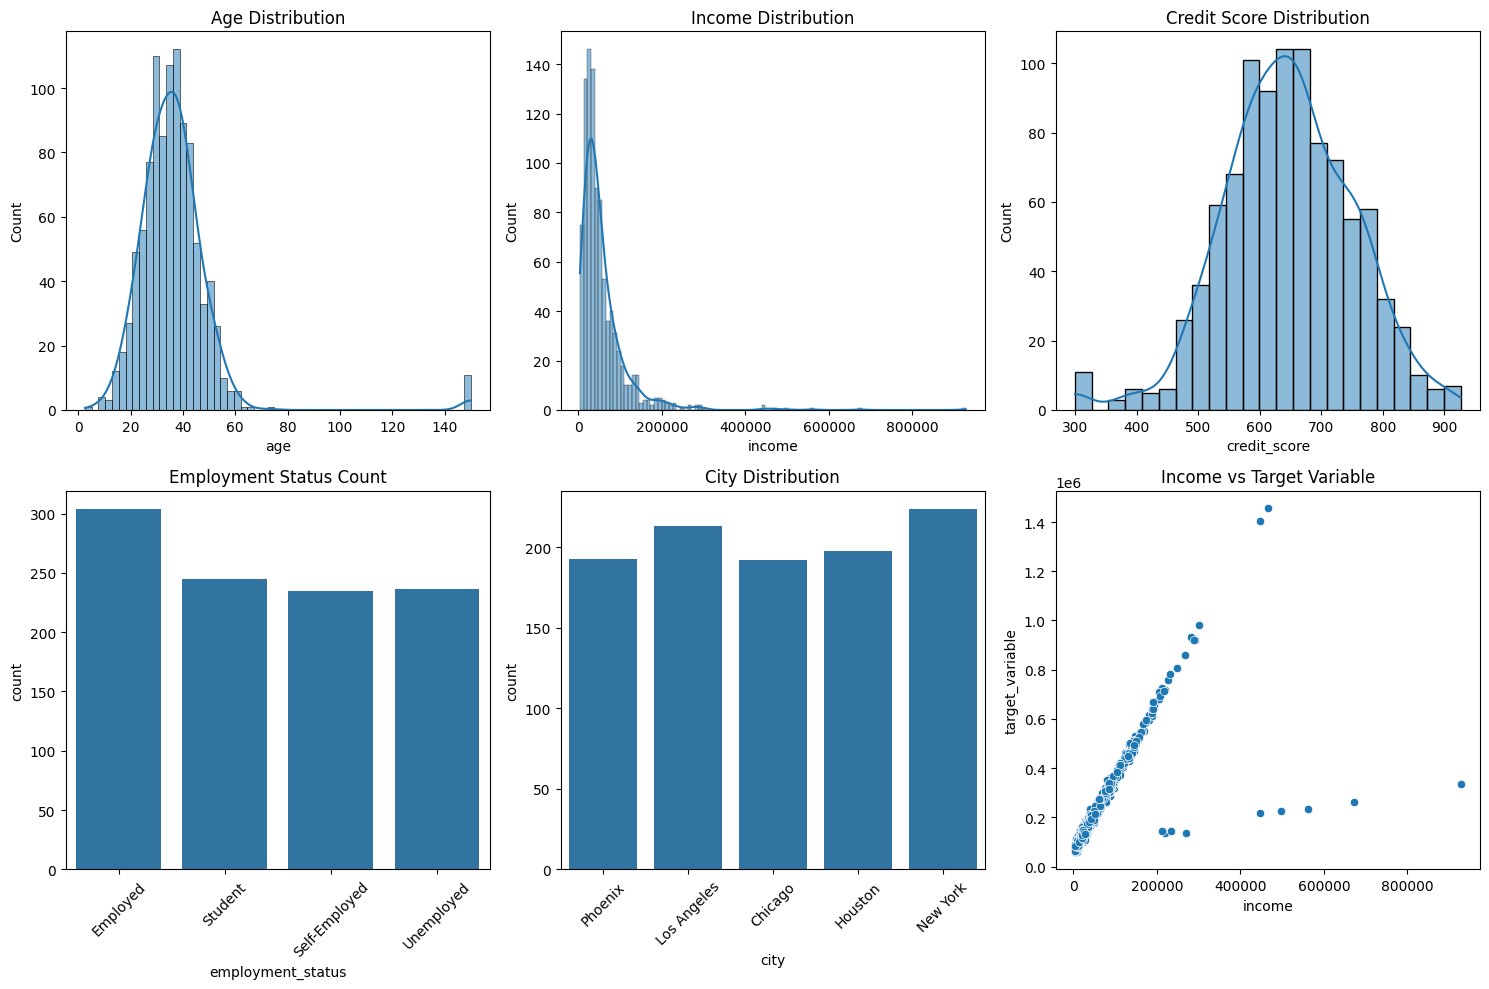

In [44]:
# 1.1 Load and inspect data
print("=== STEP 1: DATA EXPLORATION ===")
print("First 5 rows:")
print(df.head())

print("\nDataset info:")
print(df.info())

print("\nBasic statistics:")
print(df.describe())

# 1.2 Visualize initial data distribution
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
sns.histplot(df['age'], kde=True)
plt.title('Age Distribution')

plt.subplot(2, 3, 2)
sns.histplot(df['income'], kde=True)
plt.title('Income Distribution')

plt.subplot(2, 3, 3)
sns.histplot(df['credit_score'], kde=True)
plt.title('Credit Score Distribution')

plt.subplot(2, 3, 4)
sns.countplot(data=df, x='employment_status')
plt.title('Employment Status Count')
plt.xticks(rotation=45)

plt.subplot(2, 3, 5)
sns.countplot(data=df, x='city')
plt.title('City Distribution')
plt.xticks(rotation=45)

plt.subplot(2, 3, 6)
sns.scatterplot(data=df, x='income', y='target_variable')
plt.title('Income vs Target Variable')

plt.tight_layout()
plt.show()

STEP 1: DATA EXPLORATION & UNDERSTANDING
📋 Dataset Overview:
Shape: (525, 8)
Columns: ['age', 'salary', 'education_years', 'work_experience', 'credit_score', 'city', 'job_type', 'house_price']

👀 First 5 rows:
         age        salary  education_years  work_experience  credit_score  \
0  40.960570  46896.884728             14.0         5.538368    642.674789   
1  33.340828  84596.653179             19.0         1.847277    561.696986   
2  42.772262  11624.374885              8.0         3.470479    660.001649   
3  53.276358           NaN             15.0         6.318032    755.754174   
4  32.190160           NaN             18.0         4.806912    533.186391   

      city   job_type    house_price  
0  Houston  Part-Time  241506.479368  
1  Chicago  Part-Time  373214.219208  
2    Miami   Contract  160342.159243  
3  Houston  Part-Time  264628.757280  
4    Miami  Part-Time  200354.143482  

🔧 Data Types:
age                float64
salary             float64
education_years   

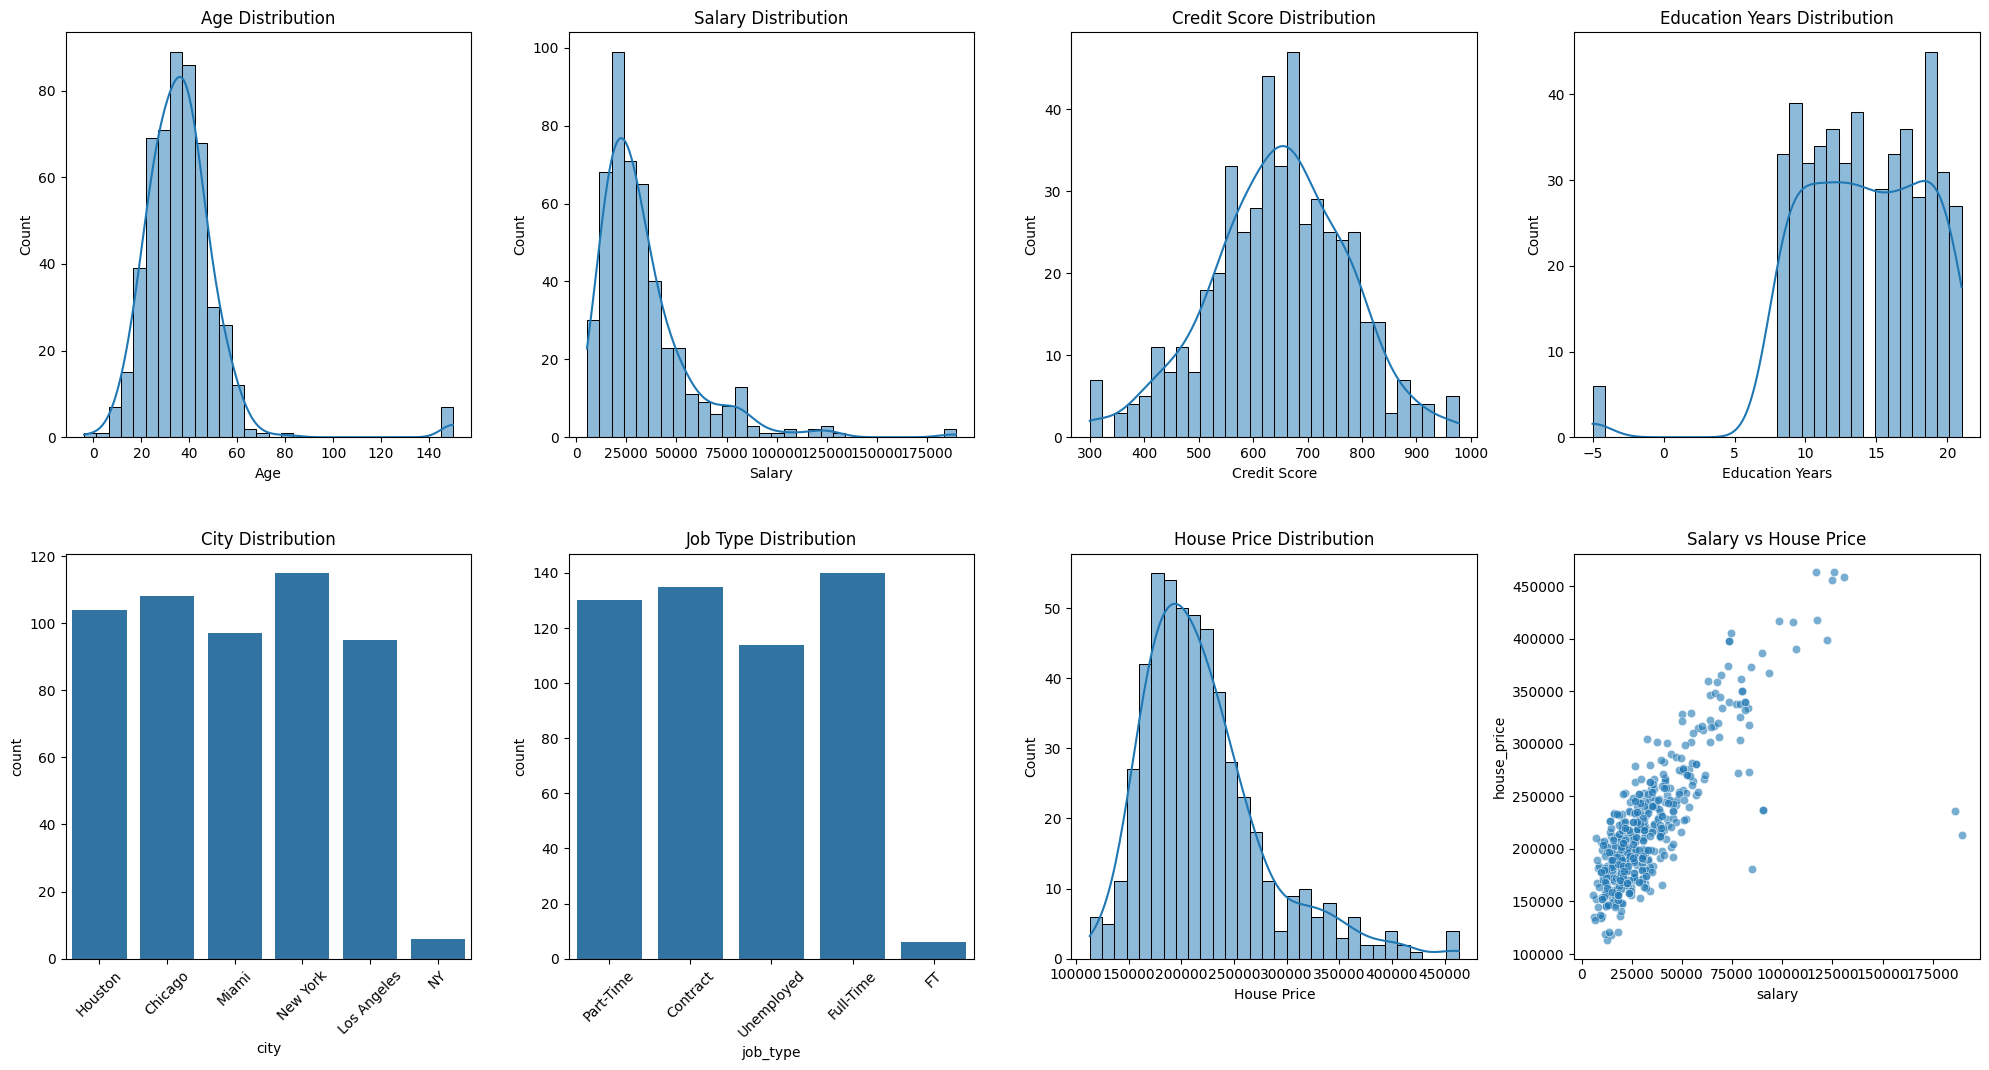

✅ Step 1 completed! We now understand our data structure.


In [47]:
print("="*50)
print("STEP 1: DATA EXPLORATION & UNDERSTANDING")
print("="*50)

# 1.1 Basic dataset information
print("📋 Dataset Overview:")
print(f"Shape: {df.shape}")  # (rows, columns)
print(f"Columns: {list(df.columns)}")

# 1.2 Display first few rows
print("\n👀 First 5 rows:")
print(df.head())

# 1.3 Data types information
print("\n🔧 Data Types:")
print(df.dtypes)

# 1.4 Basic statistics for numerical columns
print("\n📈 Basic Statistics:")
print(df.describe())

# 1.5 Check for missing values
print("\n❓ Missing Values Summary:")
missing_info = df.isnull().sum()
print(missing_info[missing_info > 0])

# 1.6 Visualize the initial data
plt.figure(figsize=(20, 15))

# Age distribution
plt.subplot(3, 4, 1)
sns.histplot(df['age'], kde=True, bins=30)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')

# Salary distribution
plt.subplot(3, 4, 2)
sns.histplot(df['salary'], kde=True, bins=30)
plt.title('Salary Distribution')
plt.xlabel('Salary')

# Credit score distribution
plt.subplot(3, 4, 3)
sns.histplot(df['credit_score'], kde=True, bins=30)
plt.title('Credit Score Distribution')
plt.xlabel('Credit Score')

# Education years
plt.subplot(3, 4, 4)
sns.histplot(df['education_years'], kde=True, bins=30)
plt.title('Education Years Distribution')
plt.xlabel('Education Years')

# Categorical data - City
plt.subplot(3, 4, 5)
sns.countplot(data=df, x='city')
plt.title('City Distribution')
plt.xticks(rotation=45)

# Categorical data - Job Type
plt.subplot(3, 4, 6)
sns.countplot(data=df, x='job_type')
plt.title('Job Type Distribution')
plt.xticks(rotation=45)

# Target variable distribution
plt.subplot(3, 4, 7)
sns.histplot(df['house_price'], kde=True, bins=30)
plt.title('House Price Distribution')
plt.xlabel('House Price')

# Relationship between salary and house price
plt.subplot(3, 4, 8)
sns.scatterplot(data=df, x='salary', y='house_price', alpha=0.6)
plt.title('Salary vs House Price')

plt.tight_layout()
plt.show()

print("✅ Step 1 completed! We now understand our data structure.")

STEP 3: DETECT AND HANDLE OUTLIERS


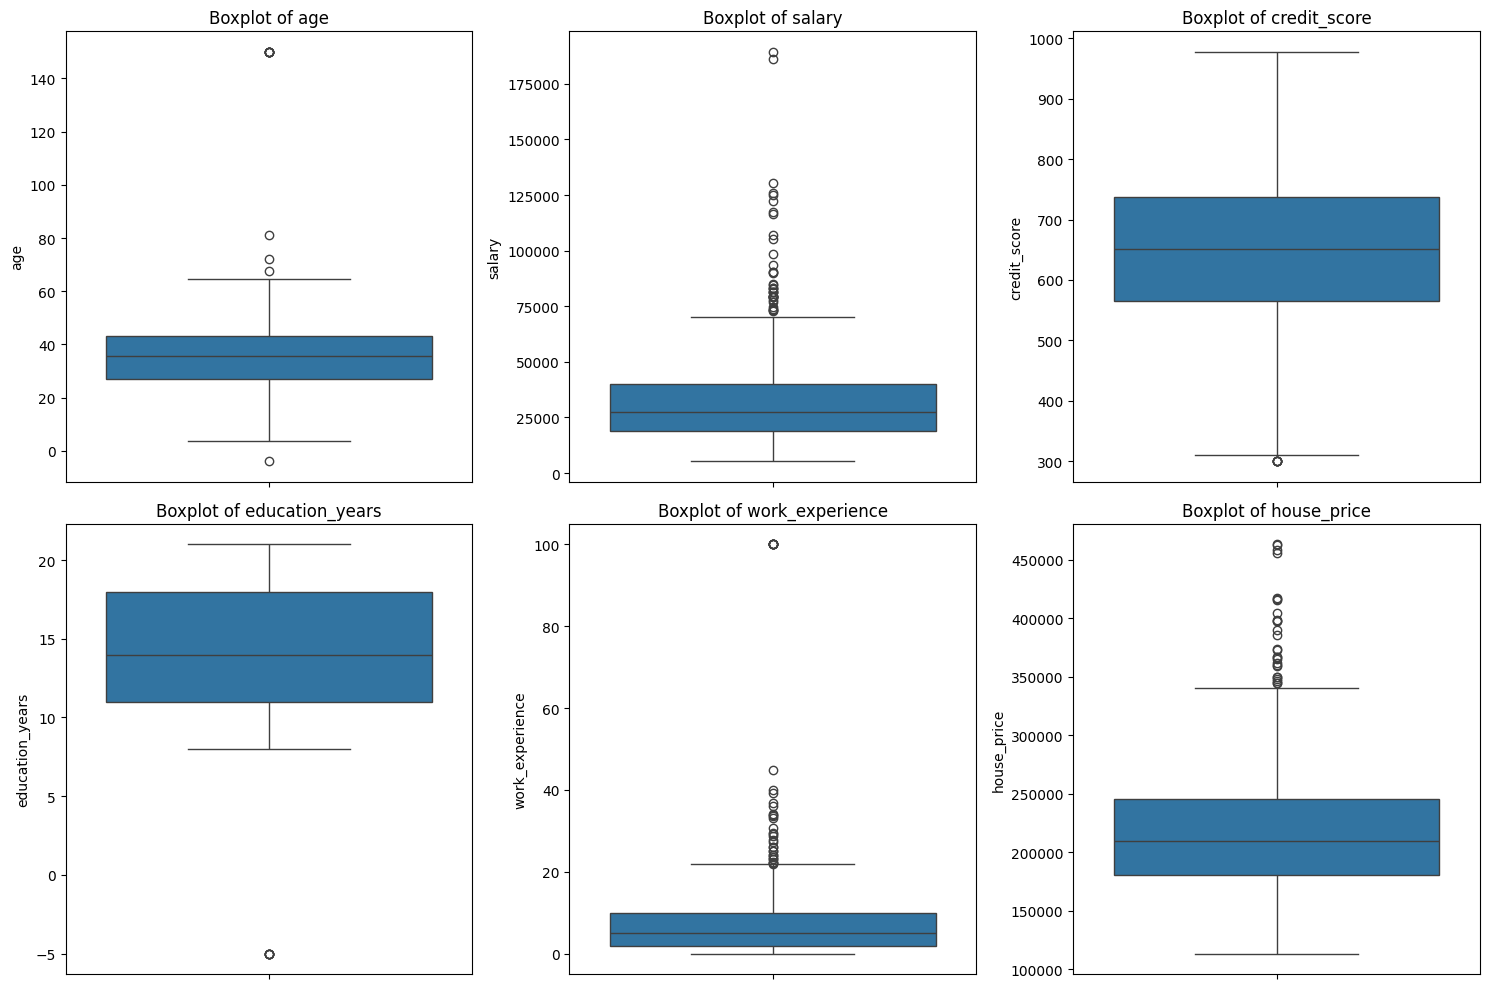

🔍 Outliers detected in each column:
age: 11 outliers (normal range: 2.64 to 67.27)
salary: 36 outliers (normal range: -12237.86 to 71246.27)
credit_score: 6 outliers (normal range: 307.26 to 994.58)
education_years: 6 outliers (normal range: 0.50 to 28.50)
work_experience: 36 outliers (normal range: -10.00 to 21.96)
house_price: 27 outliers (normal range: 81766.13 to 343844.87)

✅ Outliers handled by capping them to reasonable bounds!
📝 Explanation:
• IQR method identifies values outside 1.5*IQR from quartiles as outliers
• We 'cap' outliers instead of removing them to preserve data
• For invalid values (negative education), we use median instead


In [48]:
print("="*50)
print("STEP 3: DETECT AND HANDLE OUTLIERS")
print("="*50)

# 3.1 Function to detect outliers using IQR method
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)  # First quartile (25th percentile)
    Q3 = data[column].quantile(0.75)  # Third quartile (75th percentile)
    IQR = Q3 - Q1  # Interquartile range
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

# 3.2 Visualize outliers with boxplots
numerical_cols = ['age', 'salary', 'credit_score', 'education_years', 'work_experience', 'house_price']
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

# 3.3 Detect and handle outliers for each column
print("🔍 Outliers detected in each column:")
for col in numerical_cols:
    outliers, lower, upper = detect_outliers_iqr(df, col)
    print(f"{col}: {len(outliers)} outliers (normal range: {lower:.2f} to {upper:.2f})")
    
    # Cap outliers (bring them to the boundary values)
    df[col] = np.where(df[col] > upper, upper, 
                      np.where(df[col] < lower, lower, df[col]))
    
    # For invalid values (like negative education), set to reasonable values
    if col == 'education_years':
        df[col] = np.where(df[col] < 0, df[col].median(), df[col])
    if col == 'age':
        df[col] = np.where(df[col] > 100, df[col].median(), df[col])

print("\n✅ Outliers handled by capping them to reasonable bounds!")
print("📝 Explanation:")
print("• IQR method identifies values outside 1.5*IQR from quartiles as outliers")
print("• We 'cap' outliers instead of removing them to preserve data")
print("• For invalid values (negative education), we use median instead")

In [49]:
print("="*50)
print("STEP 4: HANDLE INVALID AND INCONSISTENT DATA")
print("="*50)

# 4.1 Fix inconsistent text data
print("🔄 Fixing inconsistent text data...")

# Fix city names
df['city'] = df['city'].replace({'NY': 'New York'})

# Fix job types
df['job_type'] = df['job_type'].replace({'FT': 'Full-Time'})

# 4.2 Remove duplicate rows
duplicates_before = df.duplicated().sum()
print(f"Duplicate rows before: {duplicates_before}")
df = df.drop_duplicates()
duplicates_after = df.duplicated().sum()
print(f"Duplicate rows after: {duplicates_after}")

# 4.3 Check for invalid values
print("\n🔍 Checking for invalid values:")
print(f"Negative education years: {(df['education_years'] < 0).sum()}")
print(f"Impossible ages (>100): {(df['age'] > 100).sum()}")
print(f"Negative work experience: {(df['work_experience'] < 0).sum()}")

print("\n✅ Data consistency check completed!")

STEP 4: HANDLE INVALID AND INCONSISTENT DATA
🔄 Fixing inconsistent text data...
Duplicate rows before: 24
Duplicate rows after: 0

🔍 Checking for invalid values:
Negative education years: 0
Impossible ages (>100): 0
Negative work experience: 0

✅ Data consistency check completed!


In [50]:
print("="*50)
print("STEP 6: PREPARE DATA FOR MACHINE LEARNING")
print("="*50)

# 6.1 Separate features (X) and target variable (y)
X = df.drop('house_price', axis=1)  # All columns except target
y = df['house_price']  # Only the target column

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

# 6.2 Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,    # 20% for testing, 80% for training
    random_state=42   # Same random split every time
)

print(f"Training set: {X_train.shape}, {y_train.shape}")
print(f"Testing set: {X_test.shape}, {y_test.shape}")

# 6.3 Scale the features (important for many ML algorithms)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Fit and transform training data
X_test_scaled = scaler.transform(X_test)        # Transform test data using same scaling

print("✅ Data preparation completed!")
print("📝 Explanation:")
print("• train_test_split: Separates data to test model on unseen data")
print("• StandardScaler: Makes all features have same scale (mean=0, std=1)")
print("• Why scale? Helps models converge faster and perform better")

STEP 6: PREPARE DATA FOR MACHINE LEARNING
Features shape: (501, 7)
Target shape: (501,)
Training set: (400, 7), (400,)
Testing set: (101, 7), (101,)


ValueError: could not convert string to float: 'Miami'